# StoryDistill — baseline evaluation: small LLM vs large LLM

**Goal:** test, rather than assume, whether a small instruction-tuned model produces lower-quality engineering subtasks than a larger teacher model on the **FleetDM** dataset. **No training or fine-tuning.**

**Pipeline:** FleetDM user stories → identical task-decomposition prompt → Qwen student vs Gemini teacher → compare both to withheld human subtasks → per-story results, aggregate statistics, paired bootstrap uncertainty, CSV outputs. An *optional* blinded model-judge stage is provided for qualitative analysis, but it is not the primary evidence.

> **Important:** The dataset includes 164 included stories and 66 excluded stories. This notebook uses **only** `fleetdm_fleet.json`, not the excluded file. A human subtask is a useful reference, not a unique perfect answer: semantic scores are proxies, not ground-truth correctness. A model can legitimately create alternative useful subtasks.

### Run in Google Colab
1. Choose **Runtime → Change runtime type → T4 GPU** (or another GPU).
2. Run installation, then authenticate. Enable **Vertex AI API** on the Google Cloud project with billing/credits.
3. Upload the original `Fleetdm dataset.zip` when prompted.
4. Fill `GOOGLE_CLOUD_PROJECT` and run. Default `N_STORIES=15` controls cost; set `None` for all 164.
5. Collect exported CSV/JSON and inspect example differences.

Model availability, Vertex location, Colab GPU quota, and API billing depend on your Google Cloud setup. This notebook has not been executed against your account.

## 1. Configuration and input dataset
The same original user-story text is provided to both systems; **human-created subtasks are never sent to either generator.**

In [ ]:
import os, json, re, time, random, zipfile, hashlib, pathlib
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from IPython.display import display

GOOGLE_CLOUD_PROJECT = "XXXX"
VERTEX_LOCATION = "global"
GEMINI_MODEL = "gemini-3.8-flash"

STUDENT_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
N_STORIES = 15             # None = all 164
RANDOM_SEED = 42
MAX_INPUT_CHARS = 6000     # same truncation rule for both models
MAX_NEW_TOKENS = 400
MATCH_THRESHOLD = 0.55    # heuristic semantic matching cutoff (not a correctness threshold)
RUN_OPTIONAL_JUDGE = False # extra teacher API calls; judge bias possible
OUT_DIR = pathlib.Path("reqdistill_results")
OUT_DIR.mkdir(exist_ok=True)
random.seed(RANDOM_SEED)
assert GOOGLE_CLOUD_PROJECT != "YOUR_PROJECT_ID", "Set GOOGLE_CLOUD_PROJECT first"

In [ ]:
from google.colab import auth, files
from google import genai
from google.genai import types

auth.authenticate_user()
client = genai.Client(vertexai=True, project=GOOGLE_CLOUD_PROJECT, location=VERTEX_LOCATION)

DATASET_ZIP = pathlib.Path("Fleetdm dataset.zip")
if not DATASET_ZIP.exists():
    print("Upload the ORIGINAL Fleetdm dataset.zip")
    uploaded = files.upload()
    assert "Fleetdm dataset.zip" in uploaded, "Please upload the original zip with this exact name"

with zipfile.ZipFile(DATASET_ZIP) as z:
    path = next((p for p in z.namelist() if p.endswith("/JSON/fleetdm_fleet.json")), None)
    assert path, "Included dataset JSONL not found in archive"
    records = [json.loads(line) for line in z.read(path).decode("utf-8").splitlines() if line.strip()]
print("Included stories:", len(records), "Human subtasks:", sum(len(r['human_created_tasks']) for r in records))
assert len(records) == 164, "Unexpected included dataset size; inspect archive before continuing"

Upload the ORIGINAL Fleetdm dataset.zip


Saving Fleetdm dataset.zip to Fleetdm dataset.zip
Included stories: 164 Human subtasks: 801


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Sample deterministically; fixed IDs for comparable reruns.
rng = random.Random(RANDOM_SEED)
selected = list(records)
rng.shuffle(selected)
if N_STORIES is not None:
    selected = selected[:N_STORIES]

def example_from_record(r):
    story = r["user_story"]
    return {
        "story_id": str(story["id"]),
        "title": story.get("title") or "",
        "description": story.get("description") or "",
        "reference_titles": [t["title"] for t in r["human_created_tasks"] if t.get("title")],
        "url": story.get("url") or r.get("link_to_user_story") or "",
    }
examples = [example_from_record(r) for r in selected]
display(pd.DataFrame([{"id":e["story_id"],"title":e["title"],"reference_count":len(e["reference_titles"])} for e in examples]).head(8))

,id,title,reference_count
0,22445,Host details page: software vulnerability seve...,3
1,4345,Surface macOS and Windows OS vulnerabilities,9
2,7766,Cache latest query results on per-query basis,17
3,36337,Android: manually enroll company-owned device ...,6
4,39372,Add Fleet-maintained apps to usage statistics,2
5,29719,Download a signed Fleet's agent (fleetd) .msi,8
6,12008,Include Kolide tables in fleetd,9
7,15920,Upcoming activities: Add MDM commands,31


## 2. Shared prompt and output parser
The same task definition, input truncation, and JSON contract are used for both models. The human references are **not** part of the prompt.

In [ ]:
SYSTEM_PROMPT = """You are an experienced software engineer decomposing a user story into actionable implementation subtasks.
Use only information provided in the story; do not invent architecture or requirements.
Produce independently actionable, concrete, nonredundant engineering subtasks.
Include testing when warranted. Respond with ONLY valid JSON of the form:
{"tasks": ["Subtask 1", "Subtask 2"]}
Do not include markdown or explanations. Prefer 2-8 concise task titles; adapt task count to story scope."""

def make_prompt(example):
    raw = f"User story title: {example['title']}\n\nUser story description:\n{example['description']}"
    return raw[:MAX_INPUT_CHARS]

def parse_tasks(raw):
    if not isinstance(raw, str):
        return [], False
    clean = raw.strip().removeprefix("```json").removeprefix("```").removesuffix("```").strip()
    candidates = [clean]
    match = re.search(r"\{.*\}", clean, flags=re.DOTALL)
    if match: candidates.append(match.group(0))
    for c in candidates:
        try:
            obj = json.loads(c)
            if isinstance(obj, dict) and isinstance(obj.get("tasks"), list):
                tasks = [s.strip() for s in obj["tasks"] if isinstance(s, str) and s.strip()]
                return list(dict.fromkeys(tasks)), True
        except (ValueError, TypeError):
            continue
    return [], False

## 3. Small-model inference (local GPU)
Uses a pretrained 0.5B-parameter instruction model. No optimizer, training data, or weight updates are involved.

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Student device:", device)
if device == "cpu": print("WARNING: CPU inference will be slow. Use a Colab GPU runtime.")
tokenizer = AutoTokenizer.from_pretrained(STUDENT_MODEL)
student = AutoModelForCausalLM.from_pretrained(
    STUDENT_MODEL, dtype=torch.float16 if device == "cuda" else torch.float32,
).to(device).eval()

def generate_student(example):
    messages = [{"role":"system", "content":SYSTEM_PROMPT}, {"role":"user", "content":make_prompt(example)}]
    encoded = tokenizer.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", truncation=True, max_length=4096).to(device)
    with torch.inference_mode():
        generated = student.generate(encoded, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                                     pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(generated[0][encoded.shape[-1]:], skip_special_tokens=True)

Student device: cpu


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

## 4. Big-model inference (Google Vertex AI)
The teacher performs the **same generation task**, rather than receiving privileged access to the human reference. API calls incur Google Cloud charges. Model IDs and availability vary by region.

In [ ]:
def generate_teacher(example):
    response = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=make_prompt(example),
        config=types.GenerateContentConfig(
            system_instruction=SYSTEM_PROMPT,
            temperature=0,
            max_output_tokens=1500,
            response_mime_type="application/json",
        ),
    )
    return response.text or ""

CACHE_FILE = OUT_DIR / "generations.json"
RUN_SIGNATURE = hashlib.sha256(json.dumps({
    "student":STUDENT_MODEL,"teacher":GEMINI_MODEL,"prompt":SYSTEM_PROMPT,
    "max_input":MAX_INPUT_CHARS,"max_new":MAX_NEW_TOKENS,"seed":RANDOM_SEED,
    "vertex_location":VERTEX_LOCATION
}, sort_keys=True).encode()).hexdigest()[:12]
if CACHE_FILE.exists():
    cache = json.loads(CACHE_FILE.read_text())
else:
    cache = {}

def save_cache():
    CACHE_FILE.write_text(json.dumps(cache, ensure_ascii=False, indent=2))

for e in tqdm(examples, desc="Running paired generation"):
    key = RUN_SIGNATURE + ":" + e["story_id"]
    data = cache.setdefault(key, {"story_id":e["story_id"], "title":e["title"]})
    if "small_raw" not in data:
        try:
            t0 = time.perf_counter(); raw = generate_student(e)
            data.update(small_raw=raw, small_latency_s=time.perf_counter()-t0)
        except Exception as exc:
            data["small_error"] = repr(exc)
        save_cache()
    if "large_raw" not in data:
        try:
            t0 = time.perf_counter(); raw = generate_teacher(e)
            data.update(large_raw=raw, large_latency_s=time.perf_counter()-t0)
        except Exception as exc:
            data["large_error"] = repr(exc)
        save_cache()
    if "small_error" in data or "large_error" in data:
        print("Failed story", e["story_id"], data.get("small_error"), data.get("large_error"))
print("Done. Generation data saved:", CACHE_FILE)

Running paired generation:   0%|          | 0/15 [00:00<?, ?it/s]

Done. Generation data saved: reqdistill_results/generations.json


## 5. Independent reference-based evaluation
Match generated task titles to human-written titles using **frozen sentence embeddings** and one-to-one Hungarian assignment. This tests semantic agreement/coverage; it is *not* a perfect measure of engineering correctness. We also measure parse success, number of generated tasks, and latency. Failed or invalid outputs receive zero matching score and are reported explicitly.

Important: The teacher is **not** involved in calculating the primary metrics. Both models are treated identically.

In [ ]:
from sentence_transformers import SentenceTransformer
from scipy.optimize import linear_sum_assignment
from matplotlib import pyplot as plt

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)

def match_metrics(predicted, reference, threshold=MATCH_THRESHOLD):
    if not predicted and not reference:
        return {"precision":1., "recall":1., "f1":1., "matched":0, "mean_similarity":1.}
    if not predicted or not reference:
        return {"precision":0., "recall":0., "f1":0., "matched":0, "mean_similarity":0.}
    vecs = embedder.encode(predicted + reference, normalize_embeddings=True, show_progress_bar=False)
    sim = np.clip(vecs[:len(predicted)] @ vecs[len(predicted):].T, -1, 1)
    # Maximize total similarity in one-to-one assignment, then threshold matched pairs.
    ii, jj = linear_sum_assignment(-sim)
    matched_sims = [float(sim[i,j]) for i,j in zip(ii,jj) if sim[i,j] >= threshold]
    count = len(matched_sims)
    precision, recall = count / len(predicted), count / len(reference)
    f1 = 2*precision*recall / (precision+recall) if precision+recall else 0.
    return {"precision":precision,"recall":recall,"f1":f1,"matched":count,
            "mean_similarity":float(np.mean(matched_sims)) if matched_sims else 0.}

rows = []
for e in examples:
    data = cache.get(RUN_SIGNATURE + ":" + e["story_id"], {})
    base = {"story_id":e["story_id"],"title":e["title"],"url":e["url"],
            "reference_count":len(e["reference_titles"])}
    for label in ["small", "large"]:
        tasks, valid = parse_tasks(data.get(label + "_raw", ""))
        score = match_metrics(tasks, e["reference_titles"])
        rows.append({**base, "model":label, "model_id":STUDENT_MODEL if label=="small" else GEMINI_MODEL,
                     "valid_json":int(valid), "task_count":len(tasks), "latency_s":data.get(label + "_latency_s", np.nan),
                     "error":data.get(label + "_error", ""), "generated_tasks":json.dumps(tasks,ensure_ascii=False),
                     "reference_tasks":json.dumps(e["reference_titles"],ensure_ascii=False), **score})
results = pd.DataFrame(rows)
results.to_csv(OUT_DIR / "per_story_results.csv",index=False)
summary = results.groupby("model").agg(
    stories=("story_id","count"), valid_json_rate=("valid_json","mean"),
    f1=("f1","mean"), precision=("precision","mean"), recall=("recall","mean"),
    avg_tasks=("task_count","mean"), avg_latency_s=("latency_s","mean"),
).round(3)
display(summary)
summary.to_csv(OUT_DIR / "summary.csv")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,stories,valid_json_rate,f1,precision,recall,avg_tasks,avg_latency_s
model,,,,,,,
large,15,1.0,0.305,0.306,0.372,5.733,10.274
small,15,1.0,0.135,0.197,0.124,5.333,29.864


## 6. Paired comparison and uncertainty
Use identical stories for both models and bootstrap *story-level paired differences*. This reports direction and uncertainty rather than assuming that the larger model must win. On 15 examples, uncertainty may be substantial.

Mean paired F1 difference (large-small): +0.170
95% paired bootstrap interval: [+0.062, +0.299]
Large higher / tie / small higher: 9 5 1


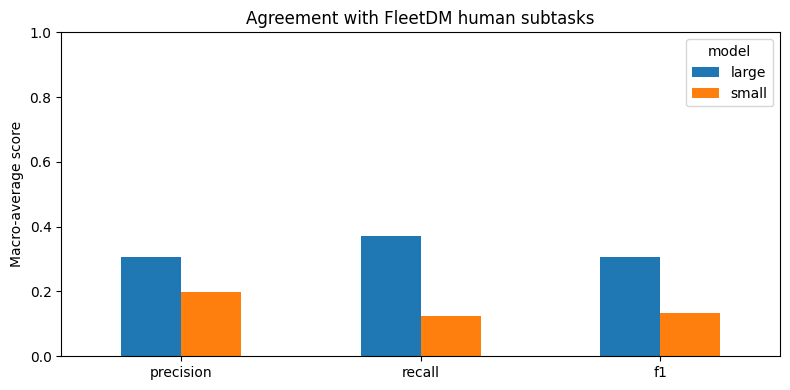

In [ ]:
pivot = results.pivot(index="story_id",columns="model",values="f1").dropna()
delta = (pivot["large"] - pivot["small"]).to_numpy()
rng = np.random.default_rng(RANDOM_SEED)
boots = np.array([rng.choice(delta,size=len(delta),replace=True).mean() for _ in range(2000)])
ci = np.quantile(boots,[0.025,0.975])
print(f"Mean paired F1 difference (large-small): {delta.mean():+.3f}")
print(f"95% paired bootstrap interval: [{ci[0]:+.3f}, {ci[1]:+.3f}]")
print("Large higher / tie / small higher:",int((delta>0).sum()),int((delta==0).sum()),int((delta<0).sum()))
ax = summary[["precision","recall","f1"]].T.plot(kind="bar", rot=0, figsize=(8,4), ylim=(0,1), title="Agreement with FleetDM human subtasks")
ax.set_ylabel("Macro-average score"); plt.tight_layout()
plt.savefig(OUT_DIR / "comparison.png",dpi=150)
plt.show()

## 7. Side-by-side examples
Inspect examples where the two models diverge. The reference set is not exhaustive and should not be treated as the only acceptable decomposition.

In [ ]:
winners = pivot.assign(gap=pivot["large"]-pivot["small"]).sort_values("gap",ascending=False)
for sid in winners.head(3).index:
    e = next(x for x in examples if x["story_id"] == sid)
    d = cache[RUN_SIGNATURE + ":" + sid]
    print("\n" + "="*90 + "\nSTORY:",e["title"],"(ID",sid+")")
    print("REFERENCE:", json.dumps(e["reference_titles"],ensure_ascii=False,indent=2))
    print("SMALL:",json.dumps(parse_tasks(d.get("small_raw",""))[0],ensure_ascii=False,indent=2))
    print("LARGE:",json.dumps(parse_tasks(d.get("large_raw",""))[0],ensure_ascii=False,indent=2))


STORY: Filter hosts by batch script execution status (ID 29198)
REFERENCE: [
  "Backend - Filter hosts by batch script execution status",
  "frontend - Filter hosts by batch script execution status",
  "Update batch script run guide"
]
SMALL: [
  "Test UI for existing behavior",
  "Test API for missing fields",
  "Test API for incorrect values"
]
LARGE: [
  "Design and implement necessary database schema migrations to support querying hosts by script batch execution status",
  "Update the hosts REST API to support script batch execution ID and status filtering, including parameter validation for required pairs and valid statuses",
  "Add backend unit and integration tests for host filtering and API parameter validation",
  "Implement the batch script execution status host filter in the UI according to Figma designs",
  "Update the batch script run feature guide documentation"
]

STORY: Host details page: software vulnerability severity filters (ID 22445)
REFERENCE: [
  "Host details p

## 8. Optional blinded quality judge (additional API cost)
A separate teacher call grades the two anonymized outputs using five criteria: specificity, completeness, actionability, nonredundancy, and groundedness (1–5 each). Order is alternated to reduce position bias. **Caution:** using the same Gemini family as generator and judge can favor Gemini-like answers; report this separately from independent human-reference metrics. For rigorous research, use human raters or a different judge family, and randomize labels/order.

In [ ]:
def blinded_judge(example, small_tasks, large_tasks):
    # Deterministic swap of displayed labels, independent of model naming.
    swap = int(hashlib.sha256(example["story_id"].encode()).hexdigest(),16) % 2 == 0
    first, second = (large_tasks, small_tasks) if swap else (small_tasks, large_tasks)
    prompt = f"""Evaluate two proposed engineering subtask decompositions for the same user story.
Only use the user story. Do not see human references. Do not prefer verbosity or number of items.
Criteria (each integer 1–5): specificity, completeness, actionability, nonredundancy, groundedness.
Return JSON {{"A":{{"specificity":1,"completeness":1,"actionability":1,"nonredundancy":1,"groundedness":1}},"B":{{...}}}}.
STORY:
{make_prompt(example)}
A:
{json.dumps(first)}
B:
{json.dumps(second)}"""
    resp = client.models.generate_content(model=GEMINI_MODEL, contents=prompt,
                config=types.GenerateContentConfig(temperature=0,response_mime_type="application/json", max_output_tokens=800))
    rating = json.loads(resp.text)
    return {"small":rating["B"] if swap else rating["A"],
            "large":rating["A"] if swap else rating["B"]}

if RUN_OPTIONAL_JUDGE:
    judgements=[]
    for e in tqdm(examples,desc="Blinded judging"):
        dat=cache[RUN_SIGNATURE+":"+e["story_id"]]
        small=parse_tasks(dat.get("small_raw",""))[0]
        large=parse_tasks(dat.get("large_raw",""))[0]
        try:
            score=blinded_judge(e,small,large)
            for model,ratings in score.items():
                judgements.append({"story_id":e["story_id"],"model":model,**ratings})
        except Exception as exc:
            print("Judge error:",e["story_id"],exc)
    if judgements:
        jdf=pd.DataFrame(judgements)
        jdf.to_csv(OUT_DIR/"optional_judge_scores.csv",index=False)
        display(jdf.groupby("model").mean(numeric_only=True).round(2))
else:
    print("Optional judge disabled. Enable RUN_OPTIONAL_JUDGE in configuration if needed.")

Optional judge disabled. Enable RUN_OPTIONAL_JUDGE in configuration if needed.


## 9. Export artifacts
These outputs can later support a **quality-guided distillation** stage. This notebook deliberately **does not** train a model, label winner candidates for training, or claim causal effects of fine-tuning.

In [ ]:
# Export complete run metadata and per-story results. Cache allows continuation after interruptions.
metadata={"student_model":STUDENT_MODEL,"teacher_model":GEMINI_MODEL,"vertex_location":VERTEX_LOCATION,
          "run_signature":RUN_SIGNATURE,"stories_evaluated":len(examples),"seed":RANDOM_SEED,
          "match_threshold":MATCH_THRESHOLD,"max_input_chars":MAX_INPUT_CHARS,
          "notes":"No fine-tuning; independent semantic reference scoring; teacher judge optional."}
(OUT_DIR / "run_metadata.json").write_text(json.dumps(metadata,indent=2))
import shutil
bundle = shutil.make_archive("reqdistill_evaluation_results", "zip", OUT_DIR)
print("Saved",bundle)
files.download(bundle)